# XRD Pipeline — Level 1: Phase Identification

**Workflow**: Load pattern → Preprocess → Fetch candidates (Materials Project) → Score/rank → **CP1: human selects phase set** → save for Rietveld (notebook 02)

All code is self-contained in this notebook. No external local modules required.

**Dependencies** (install once):
```
pip install numpy scipy matplotlib pymatgen mp-api tqdm ipywidgets dara-xrd
```
BGMN binary (for DARA) and GSAS-II (for Rietveld) require manual install — see `INSTALL.md`.

---
## 0. Imports

In [ ]:
# ! pip install --force-reinstall pymatgen-core==2026.8.30 --quiet

In [1]:
import os, re, json, pickle, hashlib, tempfile
from dataclasses import dataclass, field
from pathlib import Path
from typing import Optional

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks, savgol_filter
from tqdm.notebook import tqdm

%matplotlib inline
plt.rcParams['figure.dpi'] = 120
print('Imports OK')

Imports OK


---
## 1. Configuration

**Edit this cell for your sample.**

In [6]:
Path(r"C:\Users\amitr\AppData\Roaming\Python\Python312\site-packages\dara\bgmn\BGMNwin\BGMN.EXE").exists()

True

In [10]:
# ── Edit these ──────────────────────────────────────────────────────────────
XRD_FILE            = Path(r"D:\AMIT_WORK\projects\xrd_pipeline\new_data\M83EF-PC(B-4) 1411025_exported.xy")    # path to .xy or .xye file
ELEMENTS            = ["Li", "Ni", "Mn", "Co", "O"] # chemical system
WAVELENGTH          = 1.56                         # 'CuKa', 'MoKa', or numeric Å string
MP_API_KEY          = "1REARHn75Sriw6F4YfuTmZtnAPQifCZ6"       
BGMN_PATH           = Path(r"C:\Users\amitr\AppData\Roaming\Python\Python312\site-packages\dara\bgmn\BGMNwin\BGMN.EXE") 
TT_MIN, TT_MAX      = 10.0, 80.0                    # 2θ range to analyse (degrees)
E_HULL_MAX          = 0.1                            # energy above hull filter (eV/atom)
MAX_CANDIDATES      = 200
CACHE_DIR           = Path(".cache")
# ────────────────────────────────────────────────────────────────────────────

CACHE_DIR.mkdir(exist_ok=True)
MP_API_KEY = MP_API_KEY or os.environ.get("MP_API_KEY")

_WAVELENGTHS = {"CuKa": 1.5406, "CuKa1": 1.5406, "CuKa2": 1.5444,
                "MoKa": 0.7107, "CoKa": 1.7902, "CrKa": 2.2897, "FeKa": 1.9373}
WAVELENGTH_A = _WAVELENGTHS.get(WAVELENGTH, float(WAVELENGTH))

bgmn_available = BGMN_PATH is not None and Path(BGMN_PATH).exists()
print(f"Chemical system : {ELEMENTS}")
print(f"Wavelength      : {WAVELENGTH}  ({WAVELENGTH_A:.4f} Å)")
print(f"DARA/BGMN       : {'YES — ' + str(BGMN_PATH) if bgmn_available else 'not configured — using pymatgen scorer'}")
print(f"MP API key      : {'set' if MP_API_KEY else 'NOT SET — fetch will fail'}")

Chemical system : ['Li', 'Ni', 'Mn', 'Co', 'O']
Wavelength      : 1.56  (1.5600 Å)
DARA/BGMN       : YES — C:\Users\amitr\AppData\Roaming\Python\Python312\site-packages\dara\bgmn\BGMNwin\BGMN.EXE
MP API key      : set


---
## 2. XRD File Parser

In [11]:
@dataclass
class XRDPattern:
    two_theta: np.ndarray
    intensity: np.ndarray
    sigma:     np.ndarray
    source_file: Optional[Path] = None
    wavelength_a: float = 1.5406
    metadata: dict = field(default_factory=dict)

    @property
    def step_size(self):
        return float(np.mean(np.diff(self.two_theta)))

    @property
    def angular_range(self):
        return float(self.two_theta[0]), float(self.two_theta[-1])

    def trim(self, lo, hi):
        m = (self.two_theta >= lo) & (self.two_theta <= hi)
        return XRDPattern(self.two_theta[m], self.intensity[m], self.sigma[m],
                          self.source_file, self.wavelength_a, self.metadata.copy())


def load_xrd(path, wavelength_a=1.5406, tt_min=None, tt_max=None):
    """Parse a .xy or .xye text file → XRDPattern."""
    path = Path(path)
    rows, meta = [], {}
    _num = re.compile(r"^[\s\t]*[-+]?\d")
    with open(path, encoding="utf-8", errors="replace") as fh:
        for line in fh:
            s = line.strip()
            if not s or s.startswith("#") or not _num.match(s):
                if s:
                    meta.setdefault("header", []).append(s.lstrip("#").strip())
                continue
            try:
                rows.append([float(x) for x in s.split()])
            except ValueError:
                pass
    if not rows:
        raise ValueError(f"No numeric data found in {path}")
    arr = np.array(rows)
    tt, I = arr[:, 0], arr[:, 1]
    sig = arr[:, 2] if arr.shape[1] >= 3 else np.sqrt(np.maximum(I, 1.0))
    if not np.all(np.diff(tt) > 0):
        o = np.argsort(tt); tt, I, sig = tt[o], I[o], sig[o]
    p = XRDPattern(tt, I, sig, path, wavelength_a, meta)
    if tt_min is not None or tt_max is not None:
        p = p.trim(tt_min or tt[0], tt_max or tt[-1])
    # QC
    lo, hi = p.angular_range
    if hi - lo < 20:
        print(f"[QC WARNING] Angular range only {hi-lo:.1f}° — phase ID may be unreliable")
    if p.step_size > 0.05:
        print(f"[QC WARNING] Step size {p.step_size:.4f}° is coarse")
    return p

---
## 3. Load & Inspect Raw Pattern

[QC WARNING] Step size 0.0706° is coarse
Loaded : 993 points  |  range 10.00–79.99°  |  step 0.0706°


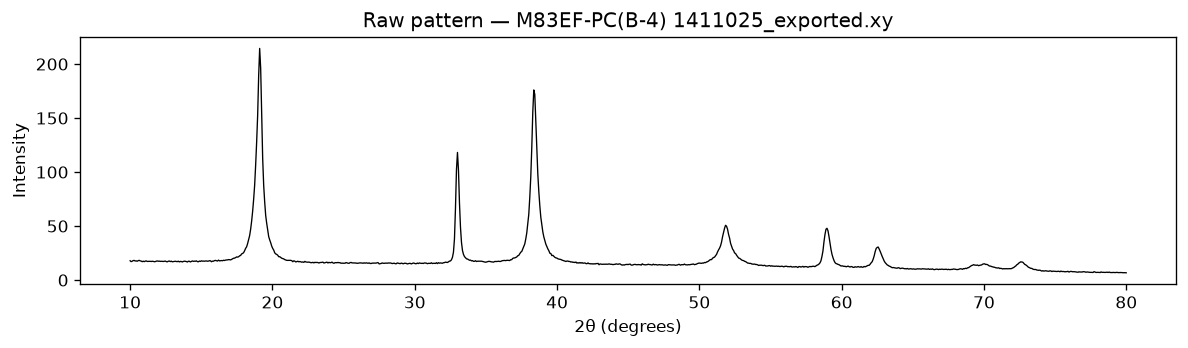

In [12]:
raw = load_xrd(XRD_FILE, wavelength_a=WAVELENGTH_A, tt_min=TT_MIN, tt_max=TT_MAX)
print(f"Loaded : {len(raw.two_theta)} points  |  range {raw.angular_range[0]:.2f}–{raw.angular_range[1]:.2f}°  |  step {raw.step_size:.4f}°")

fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(raw.two_theta, raw.intensity, lw=0.8, color='k')
ax.set_xlabel("2θ (degrees)"); ax.set_ylabel("Intensity")
ax.set_title(f"Raw pattern — {XRD_FILE.name}")
plt.tight_layout(); plt.show()

---
## 4. Preprocessing Functions

- **SNIP** background subtraction (Ryan et al., NIM A 396, 1997)
- **Rachinger** Kα2 stripping for Cu radiation

In [13]:
def snip_background(I, n_iter=24):
    """SNIP background: double-log transform → iterative clipping → inverse transform."""
    y = np.maximum(I, 0.0)
    z = np.log(np.log(np.sqrt(y + 1.0) + 1.0) + 1.0)
    n = len(z)
    for w in range(n_iter, 0, -1):
        z_new = z.copy()
        avg = (z[:n - 2*w] + z[2*w:]) / 2.0
        z_new[w:n-w] = np.minimum(z[w:n-w], avg)
        z = z_new
    bg = (np.exp(np.exp(z) - 1.0) - 1.0) ** 2 - 1.0
    return np.maximum(bg, 0.0)


def strip_kalpha2(pattern, ratio=0.5, wl_ka1=1.54056, wl_ka2=1.54439):
    """Rachinger Kα2 correction. Only for Cu (or similar dual-line) sources."""
    tt, I = pattern.two_theta, pattern.intensity.copy().astype(float)
    sin_t = np.sin(np.deg2rad(tt / 2.0))
    sin_ka2 = np.clip(sin_t * (wl_ka2 / wl_ka1), 0, 1)
    delta = np.rad2deg(2.0 * np.arcsin(sin_ka2)) - tt
    step = pattern.step_size
    for i in range(len(tt)):
        k = int(round(delta[i] / step))
        if k > 0 and (i - k) >= 0:
            I[i] = max(I[i] - ratio * I[i - k], 0.0)
    return XRDPattern(tt, I, pattern.sigma.copy(), pattern.source_file,
                      wl_ka1, {**pattern.metadata, "ka2_stripped": True})


def preprocess(pattern, do_bg=True, do_ka2=True, n_iter=24):
    """Apply SNIP background subtraction then Kα2 strip."""
    p = pattern
    bg = None
    if do_bg:
        bg = snip_background(p.intensity, n_iter)
        net = np.maximum(p.intensity - bg, 0.0)
        new_sig = np.sqrt(p.sigma**2 + np.sqrt(np.maximum(bg, 1.0))**2)
        p = XRDPattern(p.two_theta, net, new_sig, p.source_file,
                       p.wavelength_a, {**p.metadata, "background": bg})
    if do_ka2:
        p = strip_kalpha2(p)
    return p, bg

---
## 5. Preprocess & Inspect

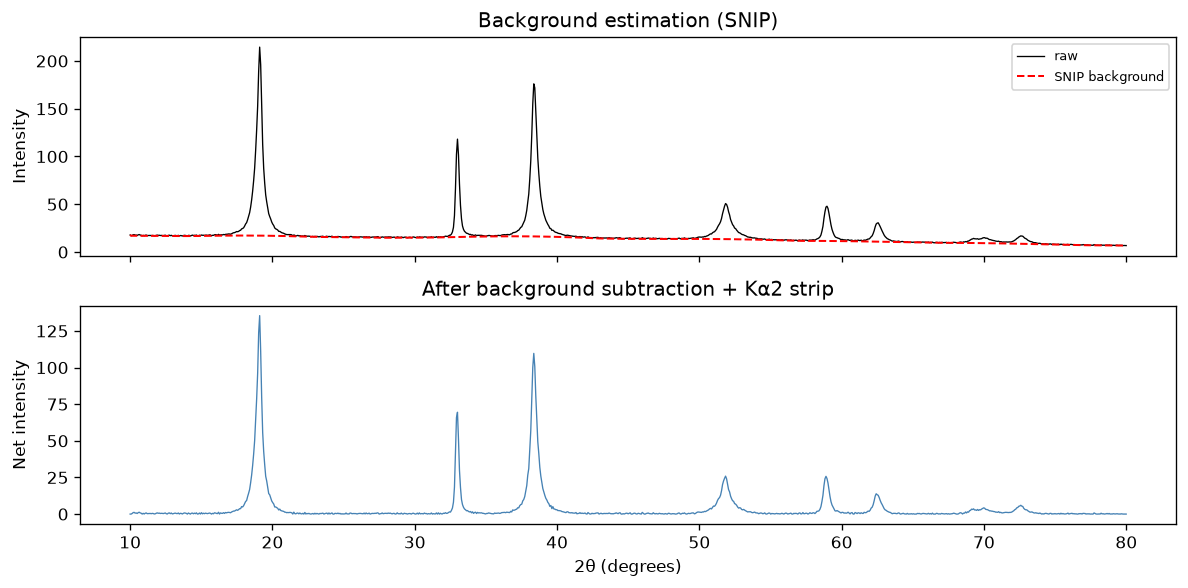

In [14]:
processed, bg = preprocess(raw, do_bg=True, do_ka2=True)

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

axes[0].plot(raw.two_theta, raw.intensity, lw=0.8, color='k', label='raw')
if bg is not None:
    axes[0].plot(raw.two_theta, bg, lw=1.2, color='r', ls='--', label='SNIP background')
axes[0].legend(fontsize=8); axes[0].set_ylabel('Intensity')
axes[0].set_title('Background estimation (SNIP)')

axes[1].plot(processed.two_theta, processed.intensity, lw=0.8, color='steelblue')
axes[1].set_xlabel('2θ (degrees)'); axes[1].set_ylabel('Net intensity')
axes[1].set_title('After background subtraction + Kα2 strip')

plt.tight_layout(); plt.show()

---
## 6. Fetch Phase Candidates from Materials Project

Results are cached locally — subsequent runs are instant.

In [15]:
@dataclass
class PhaseCandidate:
    mp_id: str
    formula: str
    space_group: str
    space_group_number: int
    energy_above_hull: float
    structure: object
    simulated_pattern: Optional[object] = None
    score: Optional[float] = None
    metadata: dict = field(default_factory=dict)


def fetch_candidates(elements, mp_api_key, e_hull_max=0.1, max_n=200,
                     cache_dir=Path(".cache"), force=False):
    """Query Materials Project for stable phases in the given chemical system."""
    tag = hashlib.md5(("-".join(sorted(elements)) + f"_{e_hull_max:.3f}").encode()).hexdigest()[:12]
    cache_file = cache_dir / f"mp_candidates_{tag}.pkl"

    if not force and cache_file.exists():
        print(f"[cache] Loading candidates from {cache_file.name}")
        with open(cache_file, "rb") as fh:
            return pickle.load(fh)

    print(f"[MP] Querying Materials Project for {elements} ...")
    from mp_api.client import MPRester
    with MPRester(mp_api_key) as mpr:
        docs = mpr.materials.summary.search(
            elements=elements,
            energy_above_hull=(0, e_hull_max),
            fields=["material_id", "formula_pretty", "symmetry",
                    "energy_above_hull", "structure"],
        )

    seen = {}
    for doc in docs:
        try:
            sym = doc.symmetry
            c = PhaseCandidate(
                mp_id=str(doc.material_id),
                formula=doc.formula_pretty,
                space_group=sym.symbol if sym else "?",
                space_group_number=sym.number if sym else 0,
                energy_above_hull=float(doc.energy_above_hull),
                structure=doc.structure,
            )
            key = (c.formula, c.space_group_number)
            if key not in seen or c.energy_above_hull < seen[key].energy_above_hull:
                seen[key] = c
        except Exception as e:
            print(f"  skip {getattr(doc, 'material_id', '?')}: {e}")

    result = sorted(seen.values(), key=lambda c: c.energy_above_hull)[:max_n]
    with open(cache_file, "wb") as fh:
        pickle.dump(result, fh)
    print(f"[cache] Saved {len(result)} candidates → {cache_file.name}")
    return result

In [16]:
candidates = fetch_candidates(
    elements=ELEMENTS,
    mp_api_key=MP_API_KEY,
    e_hull_max=E_HULL_MAX,
    max_n=MAX_CANDIDATES,
    cache_dir=CACHE_DIR,
)
print(f"\n{len(candidates)} candidates fetched")
print(f"\n{'MP-ID':<15} {'Formula':<30} {'SG#':>4}  {'Ehull (eV/at)':>14}")
print("-"*70)
for c in candidates[:10]:
    print(f"{c.mp_id:<15} {c.formula:<30} {c.space_group_number:>4}  {c.energy_above_hull:>14.4f}")

[cache] Loading candidates from mp_candidates_31ab87c782aa.pkl

8 candidates fetched

MP-ID           Formula                         SG#   Ehull (eV/at)
----------------------------------------------------------------------
mp-1120802      Li12MnCo(Ni5O12)2                12          0.0195
mp-1222667      Li5Mn2Co(NiO5)2                   1          0.0376
mp-1222510      Li3MnCoNiO6                       5          0.0491
mp-1222620      Li4MnCo2NiO8                      8          0.0817
mp-1222609      Li4MnCo2NiO8                     10          0.0857
mp-867541       Li4Mn3Co2Ni3O16                   8          0.0867
mp-776416       Li4Mn2Co3Ni3O16                   8          0.0928
mp-778315       Li10Mn3Co2Ni3O16                  1          0.0937


---
## 7. Simulate XRD Patterns (pymatgen)

Generates theoretical XRD peak positions and intensities for each candidate.  
Results are cached per (phase, wavelength).

In [17]:
def simulate_patterns(candidates, wavelength_a, tt_min, tt_max, cache_dir, force=False):
    """Simulate XRD pattern for each candidate using pymatgen XRDCalculator."""
    from pymatgen.analysis.diffraction.xrd import XRDCalculator
    calc = XRDCalculator(wavelength=wavelength_a, symprec=0.1)

    for c in tqdm(candidates, desc="Simulating patterns"):
        tag = hashlib.md5(f"{c.mp_id}_{wavelength_a:.4f}".encode()).hexdigest()[:10]
        cf = cache_dir / f"sim_{tag}.pkl"
        if not force and cf.exists():
            with open(cf, "rb") as fh:
                c.simulated_pattern = pickle.load(fh)
            continue
        try:
            pat = calc.get_pattern(c.structure, two_theta_range=(tt_min, tt_max))
            c.simulated_pattern = pat
            with open(cf, "wb") as fh:
                pickle.dump(pat, fh)
        except Exception as e:
            c.simulated_pattern = None
    return candidates


def broadened_pattern(candidate, tt_grid, sigma=0.05, use_pseudo_voigt=False,
                      U=0.01, V=-0.005, W=0.005, eta=0.5):
    """
    Build broadened simulation profile on the experimental 2θ grid.

    Parameters
    ----------
    sigma           : Gaussian sigma (degrees) used when use_pseudo_voigt=False.
    use_pseudo_voigt: If True, use Caglioti pseudo-Voigt (same as the Tier-2 scorer).
                      Requires pseudo_voigt_profile() to be defined (cell 8 / scorer cell).
    U, V, W, eta    : Caglioti / pseudo-Voigt parameters (only used when use_pseudo_voigt=True).
    """
    if candidate.simulated_pattern is None:
        return np.zeros_like(tt_grid)
    sim_tt = np.array(candidate.simulated_pattern.x)
    sim_I  = np.array(candidate.simulated_pattern.y)

    if use_pseudo_voigt:
        # pseudo_voigt_profile is defined in the scorer cell (must be run first)
        try:
            return pseudo_voigt_profile(tt_grid, sim_tt, sim_I, U=U, V=V, W=W, eta=eta)
        except NameError:
            pass   # scorer cell not yet executed — fall through to Gaussian

    # Gaussian broadening (simple, always available)
    if sim_I.max() > 0:
        sim_I = sim_I / sim_I.max()
    out = np.zeros_like(tt_grid, dtype=float)
    for t, i in zip(sim_tt, sim_I):
        out += i * np.exp(-0.5 * ((tt_grid - t) / sigma) ** 2)
    return out

In [18]:
candidates = simulate_patterns(candidates, WAVELENGTH_A, TT_MIN, TT_MAX, CACHE_DIR)

Simulating patterns:   0%|          | 0/8 [00:00<?, ?it/s]

---
## 8. Score & Rank Candidates

### What is DARA?

**DARA** (Data-driven Automated Rietveld Analysis, CederGroup/Berkeley) is a full phase-search and Rietveld-refinement engine. Its scoring relies on the **BGMN** external binary for profile-fitting; without BGMN it cannot run.

### Scorer hierarchy in this notebook

| Tier | Condition | What it does |
|------|-----------|-------------|
| **Tier 1 — DARA/BGMN** | `BGMN_PATH` set and binary exists | Full Rietveld profile fit via BGMN; returns Rwp per hypothesis |
| **Tier 2 — Profile Rwp** | `dara-xrd` installed (always) | Pseudo-Voigt broadened pymatgen simulation fit against experimental profile; computes weighted-profile R-factor (Rwp) **and** DARA's background-free RPB using `dara.utils.rpb`; no BGMN needed |
| **Tier 3 — Peak match** | Fallback if tiers above both fail | Weighted peak-position matching only (original simple scorer) |

**Tier 2 detail** — the profile Rwp scorer:
1. Builds a broadened profile from pymatgen stick pattern using a **pseudo-Voigt** peak shape with Caglioti FWHM (U, V, W parameters); this is exactly the functional form used by BGMN/GSAS-II.
2. Scales the broadened profile to the experimental data with a single least-squares scale factor (avoids absolute-intensity dependence).
3. Computes the standard Rietveld **Rwp** = sqrt(sum(w*(Iobs - Icalc)^2) / sum(w*Iobs^2)) in %, then converts to a score in [0, 1] via `score = max(0, 1 - Rwp/100)`.
4. Also reports DARA's **RPB** (Rietveld Profile without Background) using `dara.utils.rpb()` for cross-comparison with full DARA results.

The Rwp scorer is **substantially more discriminating** than simple peak matching because it penalises:
- Systematic profile-intensity mismatches (wrong relative peak heights)
- Peaks predicted by the model that do not appear in the data (false positives)
- Missing peaks that appear in data but not in simulation

In [19]:
# ── Scorer availability probe ────────────────────────────────────────────────
_DARA_AVAILABLE = False
try:
    import dara.utils as _dara_utils   # rpb() lives here; only this is needed
    _DARA_AVAILABLE = True
except ImportError:
    pass

print(f"dara-xrd package : {'available' if _DARA_AVAILABLE else 'NOT installed'}")
print(f"BGMN binary      : {'found at ' + str(BGMN_PATH) if bgmn_available else 'not configured'}")
if bgmn_available:
    print("[scorer] Tier 1  — DARA full Rietveld will be used")
elif _DARA_AVAILABLE:
    print("[scorer] Tier 2  — Profile Rwp + DARA RPB scorer will be used")
else:
    print("[scorer] Tier 3  — Simple pymatgen peak-match scorer will be used")

# ── Peak extraction ──────────────────────────────────────────────────────────
def extract_peaks(pattern, prominence=0.02, min_height=0.01):
    """Find peaks in the processed pattern. Returns (2θ positions, normalised intensities)."""
    I = pattern.intensity
    I_max = I.max()
    if I_max == 0:
        return np.array([]), np.array([])
    I_n = I / I_max
    idx, _ = find_peaks(I_n, prominence=prominence, height=min_height)
    return pattern.two_theta[idx], I_n[idx]


# ── Pseudo-Voigt profile broadening ─────────────────────────────────────────
def pseudo_voigt_profile(tt_grid, sim_tt, sim_I, U=0.01, V=-0.005, W=0.005, eta=0.5):
    """
    Build a broadened profile on tt_grid from stick pattern (sim_tt, sim_I).

    Peak shape: pseudo-Voigt = eta*Lorentzian + (1-eta)*Gaussian.
    FWHM follows the Caglioti formula: FWHM^2 = U*tan^2(theta) + V*tan(theta) + W.
    This is the same functional form used by BGMN and GSAS-II.
    """
    if len(sim_tt) == 0:
        return np.zeros_like(tt_grid, dtype=float)
    sim_I = np.asarray(sim_I, dtype=float)
    if sim_I.max() > 0:
        sim_I = sim_I / sim_I.max()

    out = np.zeros_like(tt_grid, dtype=float)
    for t, intensity in zip(sim_tt, sim_I):
        tan_t = np.tan(np.deg2rad(t / 2.0))
        fwhm2 = U * tan_t**2 + V * tan_t + W
        fwhm  = max(np.sqrt(abs(fwhm2)), 0.01)
        sigma_g = fwhm / (2.0 * np.sqrt(2.0 * np.log(2.0)))
        gamma_l = fwhm / 2.0
        dtt = tt_grid - t
        gaussian = np.exp(-0.5 * (dtt / sigma_g) ** 2)
        lorentz  = 1.0 / (1.0 + (dtt / gamma_l) ** 2)
        out += intensity * (eta * lorentz + (1.0 - eta) * gaussian)
    return out


# ── Profile Rwp scorer (Tier 2) ──────────────────────────────────────────────
def _least_squares_scale(y_calc, y_obs, w):
    """Optimal scale factor s = sum(w*y_obs*y_calc) / sum(w*y_calc^2)."""
    denom = np.sum(w * y_calc ** 2)
    if denom == 0:
        return 1.0
    return float(np.sum(w * y_obs * y_calc) / denom)


def compute_rwp(y_obs, y_calc_unscaled, sigma):
    """
    Weighted-profile R-factor (Rwp) in percent.
    Rwp = 100 * sqrt( sum(w*(yobs - s*ycalc)^2) / sum(w*yobs^2) )
    Scale factor s is solved analytically.
    """
    w = 1.0 / np.maximum(sigma ** 2, 1.0)
    s = _least_squares_scale(y_calc_unscaled, y_obs, w)
    y_calc = s * y_calc_unscaled
    num = np.sum(w * (y_obs - y_calc) ** 2)
    den = np.sum(w * y_obs ** 2)
    if den == 0:
        return 100.0
    return float(100.0 * np.sqrt(num / den))


def score_candidates_rwp(pattern, candidates, U=0.01, V=-0.005, W=0.005, eta=0.5):
    """
    Tier-2 scorer: profile Rwp using pseudo-Voigt broadening of pymatgen simulations.
    Also stores DARA RPB in candidate.metadata when dara-xrd is installed.
    """
    tt    = pattern.two_theta
    I_obs = pattern.intensity.astype(float)
    sig   = pattern.sigma.astype(float)
    y_bkg = pattern.metadata.get("background", None)
    if y_bkg is None:
        y_bkg = np.zeros_like(I_obs)

    exp_tt, _ = extract_peaks(pattern)
    print(f"[score] {len(exp_tt)} experimental peaks detected")
    print(f"[score] Tier 2 — profile Rwp scorer (pseudo-Voigt, Caglioti FWHM)")
    if _DARA_AVAILABLE:
        print(f"[score] dara.utils.rpb() available — computing DARA RPB too")

    for c in candidates:
        if c.simulated_pattern is None:
            c.score = 0.0
            c.metadata["rwp"] = 100.0
            continue

        sim_tt_arr = np.array(c.simulated_pattern.x)
        sim_I_arr  = np.array(c.simulated_pattern.y)

        y_calc_pv = pseudo_voigt_profile(tt, sim_tt_arr, sim_I_arr, U=U, V=V, W=W, eta=eta)
        rwp = compute_rwp(I_obs, y_calc_pv, sig)
        c.metadata["rwp"] = rwp

        if _DARA_AVAILABLE:
            w_obs  = 1.0 / np.maximum(sig ** 2, 1.0)
            s      = _least_squares_scale(y_calc_pv, I_obs, w_obs)
            y_scaled = s * y_calc_pv
            try:
                rpb_val = float(_dara_utils.rpb(y_scaled, I_obs, y_bkg))
            except Exception:
                rpb_val = rwp
            c.metadata["rpb"] = rpb_val

        c.score = float(max(0.0, 1.0 - rwp / 100.0))

    return sorted(candidates, key=lambda c: c.score or 0, reverse=True)


# ── Simple peak-match scorer (Tier 3 fallback) ───────────────────────────────
def peak_match_score(exp_tt, exp_I, sim_tt, sim_I, tol=0.3):
    """Weighted peak-match score in [0,1]."""
    if len(sim_tt) == 0:
        return 0.0
    sim_I = sim_I / sim_I.max() if sim_I.max() > 0 else sim_I
    exp_I = exp_I / exp_I.max() if len(exp_I) > 0 and exp_I.max() > 0 else exp_I
    total_sim = sim_I.sum()
    if total_sim == 0:
        return 0.0
    matched_w, matched_exp = 0.0, np.zeros(len(exp_tt), dtype=bool)
    for tt_s, I_s in zip(sim_tt, sim_I):
        if len(exp_tt) == 0:
            break
        j = np.argmin(np.abs(exp_tt - tt_s))
        if abs(exp_tt[j] - tt_s) <= tol:
            matched_w += I_s
            matched_exp[j] = True
    unmatched_penalty = 0.3 * (exp_I[~matched_exp].sum() / (exp_I.sum() + 1e-9))
    return float(np.clip(matched_w / total_sim - unmatched_penalty, 0, 1))


def score_candidates_pymatgen(pattern, candidates, tol=0.3):
    """Tier-3 scorer: simple weighted peak-position matching."""
    exp_tt, exp_I = extract_peaks(pattern)
    print(f"[score] {len(exp_tt)} experimental peaks detected")
    print(f"[score] Tier 3 — simple peak-match scorer (pymatgen fallback)")
    for c in candidates:
        if c.simulated_pattern is None:
            c.score = 0.0
            continue
        c.score = peak_match_score(
            exp_tt, exp_I.copy(),
            np.array(c.simulated_pattern.x), np.array(c.simulated_pattern.y), tol
        )
    return sorted(candidates, key=lambda c: c.score or 0, reverse=True)


# ── DARA/BGMN scorer (Tier 1) ────────────────────────────────────────────────
def _score_dara_bgmn(pattern, candidates, bgmn_path, elements):
    """
    Tier-1 scorer: full Rietveld via BGMN + dara-xrd.
    Falls back to Tier-2 on any error.
    """
    try:
        from dara import search_phases
        from pymatgen.io.cif import CifWriter

        work = Path(tempfile.mkdtemp(prefix="dara_"))
        xye_path = work / "pattern.xy"
        np.savetxt(xye_path,
                   np.column_stack([pattern.two_theta, pattern.intensity]),
                   fmt="%.6f", comments="")
        print(f"[DARA] Tier 1 — full BGMN Rietveld (may take several minutes)")

        cif_paths, cif_map = [], {}
        for c in candidates:
            if c.structure is None:
                continue
            cif_file = work / f"{c.mp_id}.cif"
            CifWriter(c.structure).write_file(str(cif_file))
            cif_paths.append(cif_file)
            cif_map[str(cif_file)] = c.mp_id

        wl_label = {1.5406: "Cu", 0.7107: "Mo", 1.7902: "Co",
                    2.2897: "Cr", 1.9373: "Fe"}.get(round(WAVELENGTH_A, 4), WAVELENGTH_A)

        results = search_phases(pattern_path=xye_path, phases=cif_paths,
                                wavelength=wl_label, max_phases=5)

        id_map = {c.mp_id: c for c in candidates}
        for res in (results if isinstance(results, list) else []):
            rwp = float(getattr(res, "rwp", None) or getattr(res, "Rwp", None) or 100.0)
            s   = max(0.0, 1.0 - rwp / 100.0)
            for cif_p in getattr(res, "cif_paths", []):
                pid = cif_map.get(str(cif_p))
                if pid and pid in id_map:
                    if id_map[pid].score is None or s > id_map[pid].score:
                        id_map[pid].score = s
                        id_map[pid].metadata["rwp"] = rwp

        for c in candidates:
            if c.score is None:
                c.score = 0.0

        return sorted(candidates, key=lambda c: c.score or 0, reverse=True)

    except Exception as exc:
        print(f"[DARA] Tier-1 error: {exc!r} — falling back to Tier-2")
        return score_candidates_rwp(pattern, candidates)


# ── Dispatcher ────────────────────────────────────────────────────────────────
def score_candidates(pattern, candidates, bgmn_path=None, elements=None):
    """
    Select the best available scorer:
      Tier 1 (DARA/BGMN)  — full Rietveld, requires BGMN binary + dara-xrd
      Tier 2 (Profile Rwp) — pseudo-Voigt Rwp, requires dara-xrd (no BGMN)
      Tier 3 (Peak match)  — position-only, always available
    """
    if bgmn_path and Path(bgmn_path).exists():
        return _score_dara_bgmn(pattern, candidates, bgmn_path, elements)
    if _DARA_AVAILABLE:
        return score_candidates_rwp(pattern, candidates)
    return score_candidates_pymatgen(pattern, candidates)


dara-xrd package : available
BGMN binary      : found at C:\Users\amitr\AppData\Roaming\Python\Python312\site-packages\dara\bgmn\BGMNwin\BGMN.EXE
[scorer] Tier 1  — DARA full Rietveld will be used


In [20]:
ranked = score_candidates(processed, candidates, bgmn_path=BGMN_PATH, elements=ELEMENTS)

# Determine which extra columns are populated
has_rwp = any("rwp" in c.metadata for c in ranked)
has_rpb = any("rpb" in c.metadata for c in ranked)

header = f"{'Rank':<5} {'MP-ID':<15} {'Formula':<30} {'SG#':>4}  {'Ehull':>7}  {'Score':>7}"
sep    = "-" * 75
if has_rwp:
    header += f"  {'Rwp%':>7}"
    sep    += "----------"
if has_rpb:
    header += f"  {'RPB%':>7}"
    sep    += "----------"

print(f"\n{header}")
print(sep)
for i, c in enumerate(ranked[:15]):
    row = (f"{i+1:<5} {c.mp_id:<15} {c.formula:<30} "
           f"{c.space_group_number:>4}  {c.energy_above_hull:>7.4f}  {c.score:>7.4f}")
    if has_rwp:
        row += f"  {c.metadata.get('rwp', float('nan')):>7.2f}"
    if has_rpb:
        row += f"  {c.metadata.get('rpb', float('nan')):>7.2f}"
    print(row)

[DARA] Tier 1 — full BGMN Rietveld (may take several minutes)


2026-10-01 15:55:53,377	INFO worker.py:2024 -- Started a local Ray instance.


2026-10-01 15:56:06,880 INFO dara.search.tree rpb_threshold automatically set to 1.00 based on pattern SNR.
2026-10-01 15:56:06,881 INFO dara.search.tree Detecting peaks in the pattern.


C:\Users\amitr\AppData\Roaming\Python\Python312\site-packages\dara\generate_control_file.py:56: UserWarning: Pattern contains negative or zero intensities. Setting them to 1e-6.
  warnings.warn(


2026-10-01 15:56:08,595 INFO dara.search.tree The wmax is automatically adjusted to 52.85.
2026-10-01 15:56:08,597 INFO dara.search.tree The intensity threshold is automatically set to 10.00 % of maximum peak intensity.
2026-10-01 15:56:08,597 INFO dara.search.tree Creating the root node.
2026-10-01 15:56:08,597 INFO dara.search.tree Refining all the phases in the dataset.


(remote_do_refinement_no_saving pid=38164) C:\Users\amitr\AppData\Roaming\Python\Python312\site-packages\dara\generate_control_file.py:56: UserWarning: Pattern contains negative or zero intensities. Setting them to 1e-6.
(remote_do_refinement_no_saving pid=38164)   warnings.warn(
(remote_do_refinement_no_saving pid=38164) C:\Users\amitr\AppData\Roaming\Python\Python312\site-packages\dara\generate_control_file.py:56: UserWarning: Pattern contains negative or zero intensities. Setting them to 1e-6. [repeated 15x across cluster] (Ray deduplicates logs by default. Set RAY_DEDUP_LOGS=0 to disable log deduplication, or see https://docs.ray.io/en/master/ray-observability/user-guides/configure-logging.html#log-deduplication for more options.)
(remote_do_refinement_no_saving pid=38164)   warnings.warn( [repeated 15x across cluster]


[DARA] Tier-1 error: ZeroDivisionError('division by zero') — falling back to Tier-2
[score] 8 experimental peaks detected
[score] Tier 2 — profile Rwp scorer (pseudo-Voigt, Caglioti FWHM)
[score] dara.utils.rpb() available — computing DARA RPB too

Rank  MP-ID           Formula                         SG#    Ehull    Score     Rwp%     RPB%
-----------------------------------------------------------------------------------------------
1     mp-1120802      Li12MnCo(Ni5O12)2                12   0.0195   0.0153    98.47    30.77
2     mp-778315       Li10Mn3Co2Ni3O16                  1   0.0937   0.0138    98.62    30.20
3     mp-776416       Li4Mn2Co3Ni3O16                   8   0.0928   0.0127    98.73    30.49
4     mp-867541       Li4Mn3Co2Ni3O16                   8   0.0867   0.0099    99.01    30.22
5     mp-1222667      Li5Mn2Co(NiO5)2                   1   0.0376   0.0077    99.23    30.68
6     mp-1222510      Li3MnCoNiO6                       5   0.0491   0.0047    99.53    30.

---
## 9. Visualise Top Candidates

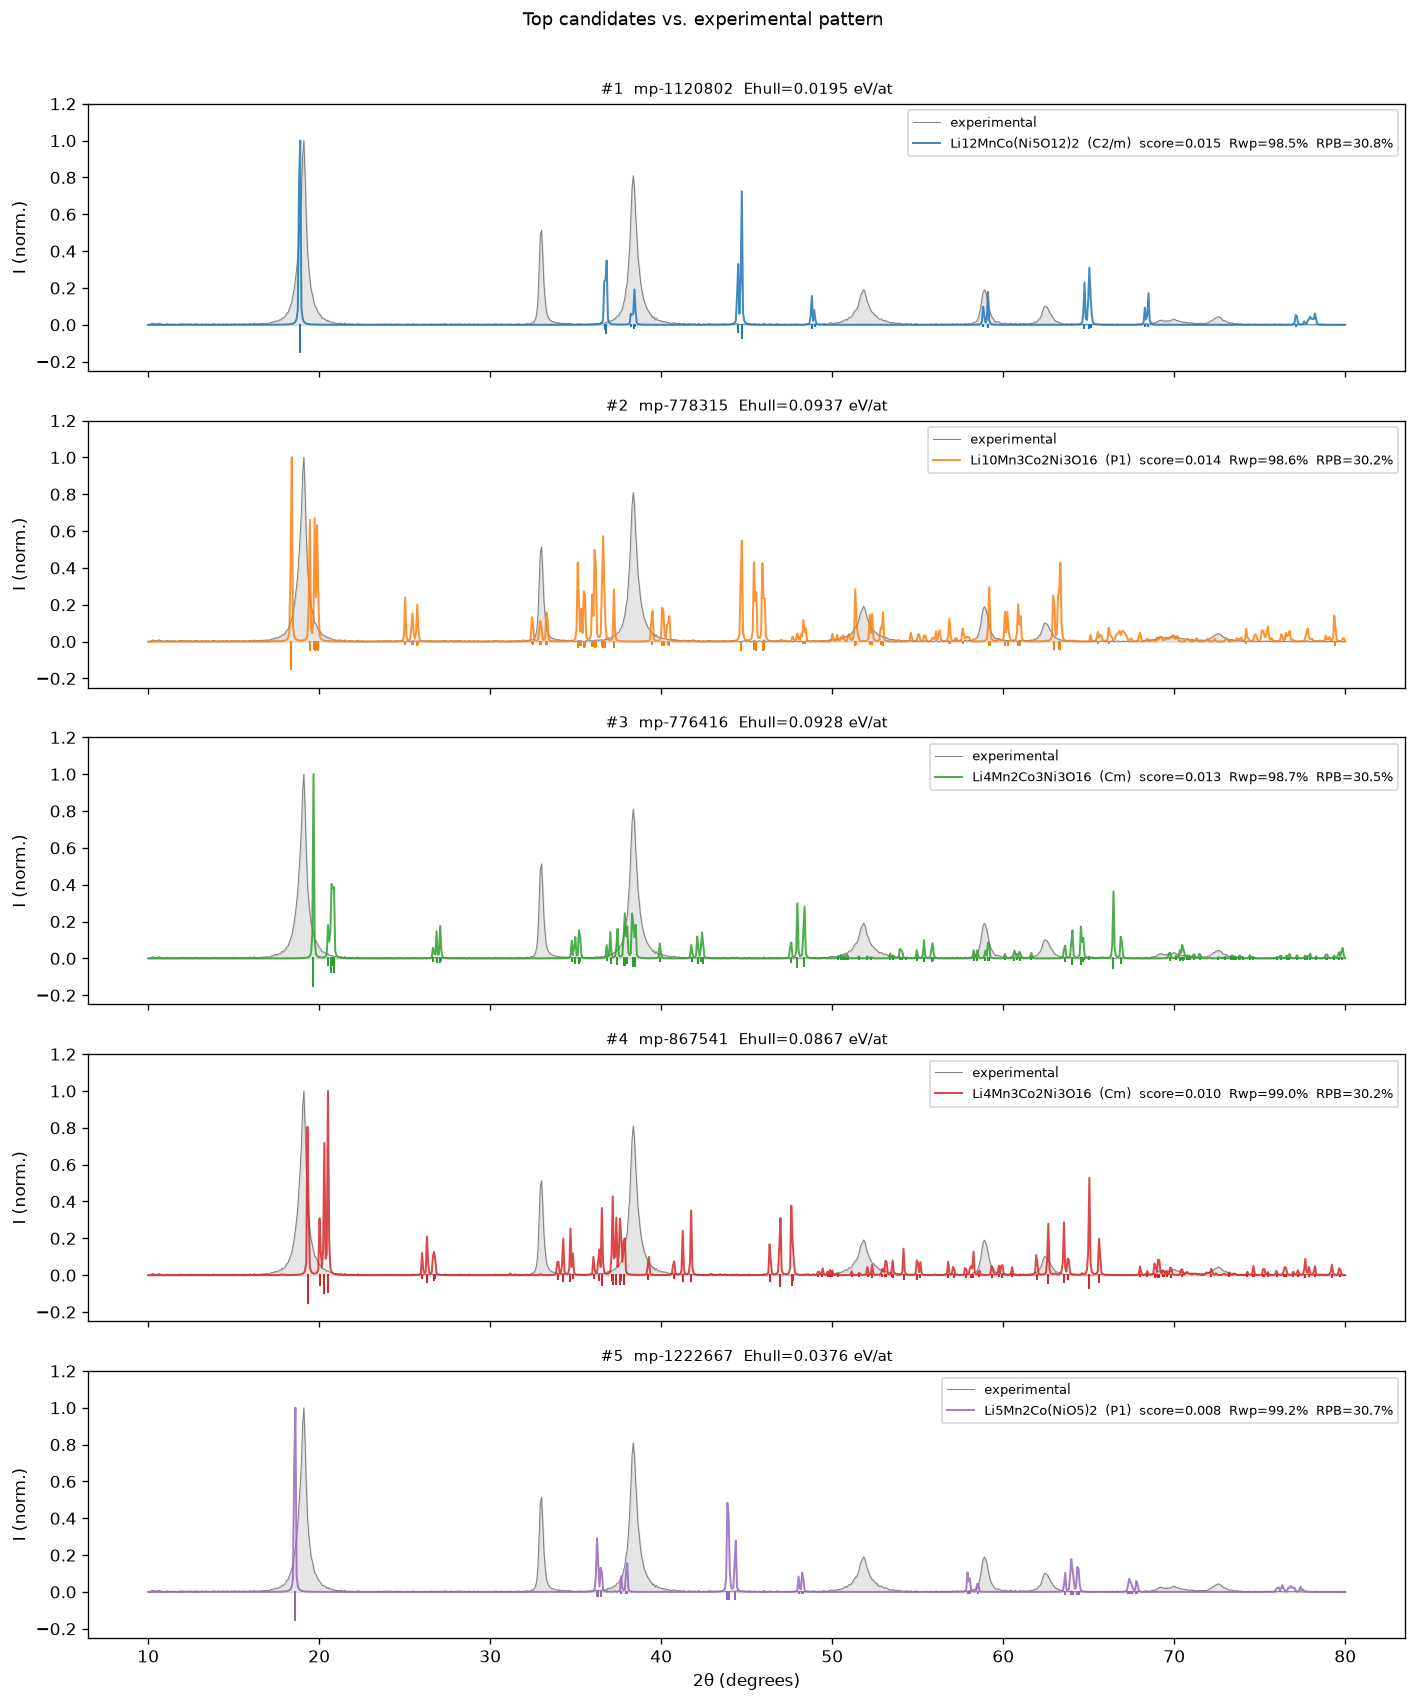

In [21]:
TOP_N = 5
top = [c for c in ranked[:TOP_N] if c.simulated_pattern is not None]

exp_tt = processed.two_theta
exp_I  = processed.intensity / (processed.intensity.max() or 1)
cmap   = plt.cm.tab10

fig, axes = plt.subplots(len(top), 1, figsize=(12, 2.8 * len(top)), sharex=True)
if len(top) == 1:
    axes = [axes]

for i, (ax, c) in enumerate(zip(axes, top)):
    color = cmap(i)
    ax.fill_between(exp_tt, exp_I, alpha=0.2, color='grey')
    ax.plot(exp_tt, exp_I, lw=0.6, color='grey', label='experimental')

    # Tick marks below axis
    for tt_p, I_p in zip(np.array(c.simulated_pattern.x), np.array(c.simulated_pattern.y) / 100):
        ax.plot([tt_p, tt_p], [0, -0.15 * I_p], color=color, lw=1.2)

    # Broadened overlay — use pseudo-Voigt when scorer is Tier 2 for consistency
    sim_b = broadened_pattern(c, exp_tt, use_pseudo_voigt=_DARA_AVAILABLE)
    if sim_b.max() > 0:
        sim_b /= sim_b.max()

    # Build legend label
    rwp_str = f"  Rwp={c.metadata['rwp']:.1f}%" if "rwp" in c.metadata else ""
    rpb_str = f"  RPB={c.metadata['rpb']:.1f}%" if "rpb" in c.metadata else ""
    lbl = f"{c.formula}  ({c.space_group})  score={c.score:.3f}{rwp_str}{rpb_str}"

    ax.plot(exp_tt, sim_b, color=color, lw=1.2, alpha=0.85, label=lbl)
    ax.set_ylim(-0.25, 1.2)
    ax.set_ylabel('I (norm.)')
    ax.legend(loc='upper right', fontsize=8)
    ax.set_title(f"#{i+1}  {c.mp_id}  Ehull={c.energy_above_hull:.4f} eV/at", fontsize=9)

axes[-1].set_xlabel('2\u03b8 (degrees)')
plt.suptitle('Top candidates vs. experimental pattern', fontsize=11, y=1.01)
plt.tight_layout()
plt.show()

---
## 10. Peak Map — Experimental vs. Single Candidate

Change `CANDIDATE_IDX` to inspect any ranked candidate.

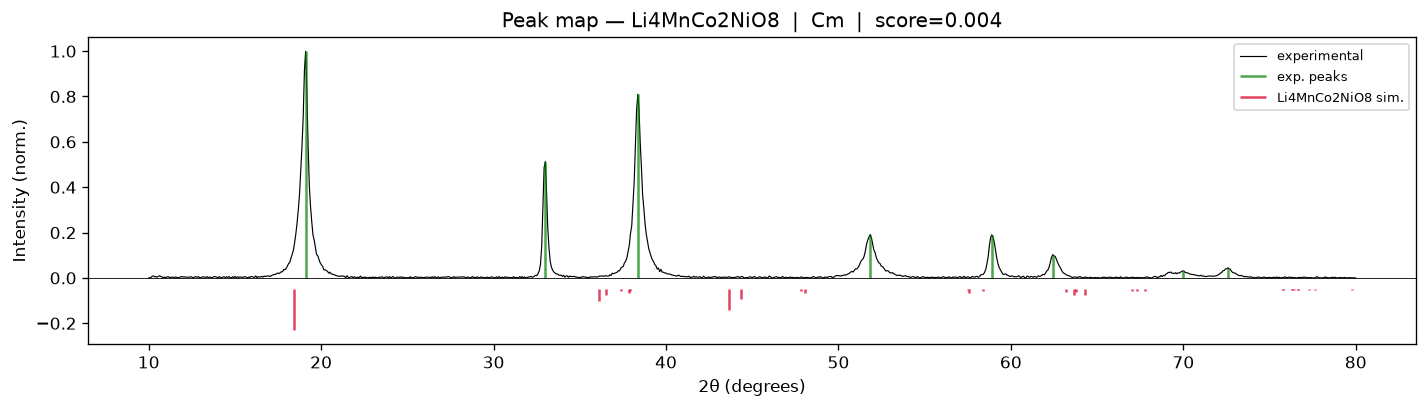

Experimental peaks : 8
Simulated peaks    : 114


In [24]:
CANDIDATE_IDX = 7

c = ranked[CANDIDATE_IDX]
exp_pk_tt, exp_pk_I = extract_peaks(processed)
sim_tt = np.array(c.simulated_pattern.x)
sim_I  = np.array(c.simulated_pattern.y) / 100.0

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(processed.two_theta, processed.intensity / processed.intensity.max(), lw=0.7, color='k', label='experimental')
ax.vlines(exp_pk_tt,  0,  exp_pk_I,          color='green',  lw=1.5, alpha=0.7, label='exp. peaks')
ax.vlines(sim_tt,    -0.05, -0.05 - 0.18*sim_I, color='crimson', lw=1.5, alpha=0.8, label=f'{c.formula} sim.')
ax.axhline(0, color='k', lw=0.5)
ax.set_xlabel('2θ (degrees)'); ax.set_ylabel('Intensity (norm.)')
ax.set_title(f'Peak map — {c.formula}  |  {c.space_group}  |  score={c.score:.3f}')
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

print(f"Experimental peaks : {len(exp_pk_tt)}")
print(f"Simulated peaks    : {len(sim_tt)}")